# Import modules

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import mean_absolute_error, root_mean_squared_error
from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree

# Define a seed 

In [2]:
SEED: int = 42069

# Define path to data from current directory 

In [3]:
euro_test_path: str = "../data/EuroTest.csv"
euro_training_path: str = "../data/EuroTraining.csv"
handball_long_path: str = "../data/handball_long.csv"
handball_wide_path: str = "../data/handball_wide.csv"
tennis_path: str = "../data/SlamsData.csv"

# Load data in pandas DataFrame 

In [4]:
euro_test_df: pd.DataFrame = pd.read_csv(euro_test_path)
euro_training_df: pd.DataFrame = pd.read_csv(euro_training_path)
handball_long_df: pd.DataFrame = pd.read_csv(handball_long_path)
handball_wide_df: pd.DataFrame = pd.read_csv(handball_wide_path)
tennis_df: pd.DataFrame = pd.read_csv(tennis_path)

# Define features

In [5]:
handball_features: list[str] = [
    "bet.probs.diff",
    "season"
]
hand_feat_df: pd.DataFrame = handball_wide_df[handball_features]

euro_features: list[str] = [
    "GroupStage",
    "GDP",
    "MarketValue", 
    "FifaRank", 
    "UefaPoints",
    "CLPlayers"
]
euro_feat_df: pd.DataFrame = euro_training_df[euro_features]

tennis_features: list[str] = [
    "rank", 
    "points", 
    "elo", 
    "age.30"
]
tennis_feat_df: pd.DataFrame = tennis_df[tennis_features]

# Define predictors

In [6]:
handball_response: str = "scorediff"
hand_res: pd.Series = handball_wide_df[handball_response]

euro_response: str = "Goals"
euro_res: pd.Series = euro_training_df[euro_response]

tennis_response: str = "win"
tennis_res: pd.Series = tennis_df[tennis_response]

# define regression trees for handball/euro and classification tree for tennis

In [7]:
params_dict: dict[str, int] = {
    "random_state": SEED,
    "min_samples_split": 10,
    "max_depth": 5,
    "min_samples_leaf": 5
}
handball_tree: DecisionTreeRegressor = DecisionTreeRegressor(
    **params_dict
)
euro_tree: DecisionTreeRegressor = DecisionTreeRegressor(
    **params_dict
)

tennis_tree: DecisionTreeClassifier = DecisionTreeClassifier(
    **params_dict
)

# Fit the trees 

In [8]:
handball_tree.fit(hand_feat_df, hand_res) 

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",5
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",10
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",5
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42069
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree wit

In [9]:
euro_tree.fit(euro_feat_df, euro_res)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",5
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",10
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",5
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42069
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree wit

In [10]:
tennis_tree.fit(tennis_feat_df, tennis_res)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",5
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",10
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",5
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42069
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of sample

In [11]:
tennis_tree.get_n_leaves()

np.int64(32)

# Plot trees

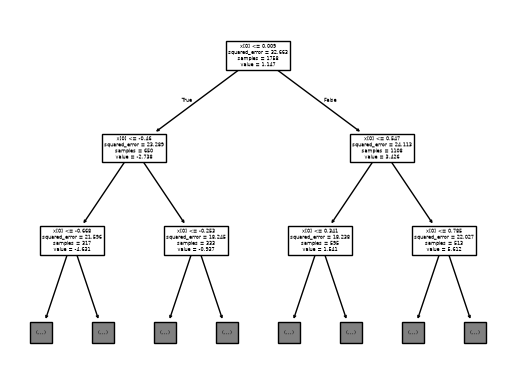

In [12]:
plot_tree(handball_tree, max_depth=2)
plt.show()

# Predict handball(scorediff), euro(Goals), tennis(win)

In [13]:
handball_pred: np.ndarray = handball_tree.predict(hand_feat_df)
euro_pred: np.ndarray = euro_tree.predict(euro_feat_df)
tennis_pred: np.ndarray = tennis_tree.predict(tennis_feat_df)

# calc diff of response column and correct tennis predictions

In [14]:
handball_mae: float = mean_absolute_error(hand_res, handball_pred)
handball_rmse: float = root_mean_squared_error(hand_res, handball_pred)

euro_mae: float = mean_absolute_error(euro_res, euro_pred)
euro_rmse: float = root_mean_squared_error(euro_res, euro_pred)

tennis_ratio: np.float64 = (tennis_pred == tennis_res).sum() / tennis_df.shape[0]

In [15]:
print(handball_mae, handball_rmse)
print(euro_mae, euro_rmse)
print(tennis_ratio)

3.345548312884134 4.265813748603035
0.7376438587108778 0.9240275113589991
0.7554380664652568


identify the matches with the largest overestimation and underestimation. For the tennis data,
identify those predictions with the most extreme predicted winning probabilities. Discuss possible
reasons based on the data

In [16]:
hand_10_largest_diff_idx: pd.Series = (handball_pred - hand_res).abs().nlargest(10)
handball_wide_df.loc[hand_10_largest_diff_idx.index]

,matchid,hometeam,awayteam,season,homegoals,awaygoals,scorediff,bet.probs.diff
1310,1324,HSG Wetzlar,Hannover-Burgdorf,2021,38,16,22,0.220076
1407,1424,TBV Lemgo Lippe,GWD Minden,2021,20,32,-12,0.570115
1415,1433,TBV Lemgo Lippe,SC Magdeburg,2021,25,44,-19,-0.547495
160,161,Rhein-Neckar Löwen,TBV Lemgo Lippe,2017,38,17,21,0.833881
1067,1078,SC Magdeburg,HSC 2000 Coburg,2020,43,22,21,0.850185
1725,1759,SG Flensburg-Handewitt,THW Kiel,2022,36,23,13,-0.058331
1457,1477,TVB Stuttgart,Hannover-Burgdorf,2021,22,34,-12,0.260164
984,995,HSG Wetzlar,Eulen Ludwigshafen,2020,29,11,18,0.739844
1498,1520,Füchse Berlin,Rhein-Neckar Löwen,2022,38,24,14,0.391377
528,529,THW Kiel,GWD Minden,2018,39,19,20,0.844255


In [23]:
euro_10_largest_diff: pd.Series = (euro_pred - euro_res).abs().nlargest(10)
idx: pd.Index = euro_10_largest_diff.index.append(
    euro_10_largest_diff.index.map(lambda x: x + pow(-1, x%2))
).sort_values()
euro_training_df.iloc[idx]

,Goals,Team,Opponent,Year,GroupStage,GDP,MarketValue,FifaRank,UefaPoints,CLPlayers
26,3,Netherlands,Italy,2008,1,0.317074,-0.413355,7,-25105,1.000000
27,0,Italy,Netherlands,2008,1,-0.317074,0.413355,-7,25105,-1.000000
30,4,Netherlands,France,2008,1,0.182522,-0.332220,3,-14245,-5.000000
31,1,France,Netherlands,2008,1,-0.182522,0.332220,-3,14245,5.000000
82,2,Croatia,England,2004,1,-1.381492,-1.466337,13,-44778,-3.000000
83,4,England,Croatia,2004,1,1.381492,1.466337,-13,44778,3.000000
88,5,Sweden,Bulgaria,2004,1,2.517036,0.630346,-17,-3282,0.000000
89,0,Bulgaria,Sweden,2004,1,-2.517036,-0.630346,17,3282,0.000000
126,4,Russia,Czech Republic,2012,1,-0.453279,0.471423,-14,18157,-1.000000
127,1,Czech Republic,Russia,2012,1,0.453279,-0.471423,14,-18157,1.000000


In [18]:
# tennis
tennis_pred_prob: np.ndarray = tennis_tree.predict_proba(tennis_feat_df)[:,1]
tennis_10_biggest_diff: pd.Series = (tennis_pred_prob - tennis_res).abs().nlargest(10)

tennis_df.loc[tennis_10_biggest_diff.index]

,player.1,player.2,year,tournament,surface,win,sets.1,sets.2,rank,points,elo,prob,age.30,AvgProb.1,AvgProb.2,B365.1,B365.2
1471,Denis Istomin,Novak Djokovic,2017,Australian Open,Hard,1,3,2,115,-11282,-772.628817,-0.909050,0.030137,0.045475,0.954525,23.00,1.010
1538,Dennis Novikov,Jerzy Janowicz,2012,US Open,Hard,1,3,1,1012,-596,-616.478947,-0.808394,2.980822,0.095803,0.904197,11.00,1.050
1753,Dustin Brown,Rafael Nadal,2015,Wimbledon,Grass,1,3,1,92,-2626,-540.253287,-0.717587,-0.353612,0.141207,0.858793,7.00,1.110
1803,Ernests Gulbis,Tomas Berdych,2012,Wimbledon,Grass,1,3,0,80,-4089,-453.982278,-0.833066,2.948881,0.083467,0.916533,13.00,1.040
4186,Maxime Cressy,Pablo Carreno Busta,2021,US Open,Hard,1,3,2,139,-2821,-435.856596,-0.738295,5.547945,0.130852,0.869148,7.00,1.100
5734,Ryan Harrison,Milos Raonic,2016,US Open,Hard,1,3,1,114,-4296,-472.841910,-0.778926,1.357961,0.110537,0.889463,9.00,1.070
5783,Sam Querrey,Novak Djokovic,2016,Wimbledon,Grass,1,3,1,40,-15875,-680.786959,-0.907297,0.379138,0.046352,0.953648,26.00,1.010
6088,Steve Darcis,Rafael Nadal,2013,Wimbledon,Grass,1,3,0,130,-6477,-679.195886,-0.906870,-2.224658,0.046565,0.953435,29.00,1.002
436,Roger Federer,Andreas Seppi,2015,Australian Open,Hard,0,1,3,-44,8960,459.271437,0.866667,2.539344,0.933333,0.066667,1.02,17.000
1793,Juan Martin del Potro,Ernests Gulbis,2017,Wimbledon,Grass,0,0,3,-557,1275,409.821007,0.692308,0.065574,0.846154,0.153846,1.12,6.000


In [19]:
tennis_df.head()

,player.1,player.2,year,tournament,surface,win,sets.1,sets.2,rank,points,elo,prob,age.30,AvgProb.1,AvgProb.2,B365.1,B365.2
0,Adam Pavlasek,Ernesto Escobedo,2017,Wimbledon,Grass,1,3,1,62,-275,-149.309441,-0.339535,-1.736986,0.330233,0.669767,2.75,1.44
1,Mirza Basic,Adam Pavlasek,2018,French Open,Clay,0,1,3,-104,400,67.578613,-0.280193,-3.241096,0.359903,0.640097,2.62,1.50
2,Roberto Carballes Baena,Adam Pavlasek,2016,French Open,Clay,0,2,3,-18,81,47.921054,0.178571,-1.545812,0.589286,0.410714,1.53,2.37
3,Adam Walton,Federico Coria,2024,Wimbledon,Grass,1,3,0,29,-169,-20.076166,0.521073,2.478142,0.760536,0.239464,1.25,4.00
4,Alexander Shevchenko,Adrian Mannarino,2023,Wimbledon,Grass,0,0,3,62,-489,-55.552644,-0.569395,2.389041,0.215302,0.784698,4.50,1.20


# handball create scatter predicted / actual scorediff with bisect line

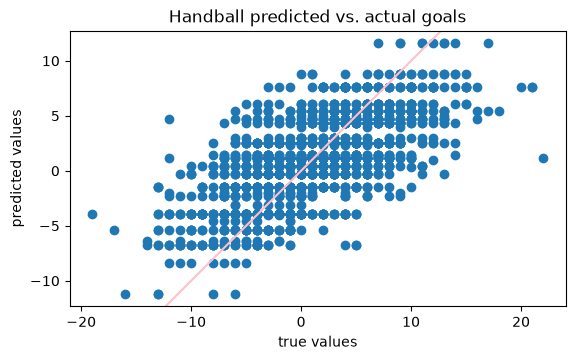

In [20]:
fig, ax = plt.subplots()
ax.scatter(hand_res, handball_pred)
ax.set_title("Handball predicted vs. actual goals")
ax.set_xlabel("true values")
ax.set_ylabel("predicted values")
ax.axline((0,0), slope=1, linestyle="-", color="pink")
ax.set_aspect("equal", adjustable="box")
plt.show()

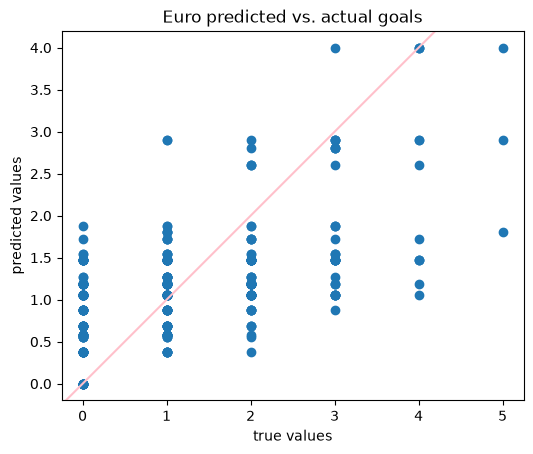

In [21]:
fig, ax = plt.subplots()
ax.scatter(euro_res, euro_pred)
ax.set_title("Euro predicted vs. actual goals")
ax.set_xlabel("true values")
ax.set_ylabel("predicted values")
ax.axline((0,0), slope=1, linestyle="-", color="pink")
ax.set_aspect("equal", adjustable="box")
plt.show()

<Axes: xlabel='win', ylabel='pred_proba'>

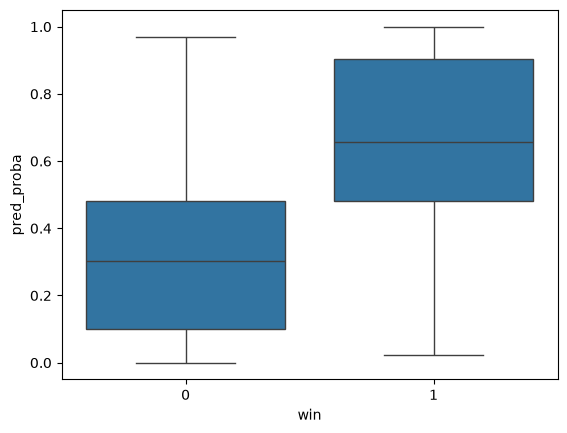

In [22]:
tennis_df["pred_proba"] = tennis_pred_prob
sns.boxplot(x="win", y="pred_proba", data=tennis_df)

# Task 2 

# examine feature importance measure for euro tree